In [1]:
# Runtime / reproducibility configuration
import os
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

SEED = 42
BATCH_SIZE = 128
EPOCHS = 20
LEARNING_RATE = 0.1
WEIGHT_DECAY = 5e-4
MOMENTUM = 0.9
TRAIN_FRACTION = 0.9       # 45,000 train / 5,000 validation images
NUM_WORKERS = 2            # If DataLoader hangs in a different environment, set to 0
DEVICE_MODE = "auto"       # "auto", "cuda", "cpu", or "tpu"
DATA_DIR = Path("/kaggle/working/data")
OUTPUT_DIR = Path("/kaggle/working")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Deterministic behavior may trade some speed for reproducibility.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

def choose_device(mode="auto"):
    mode = mode.lower()
    if mode == "cpu":
        return torch.device("cpu")
    if mode == "cuda":
        if not torch.cuda.is_available():
            raise RuntimeError("CUDA was requested, but torch.cuda.is_available() is False. Enable a Kaggle GPU accelerator.")
        return torch.device("cuda")
    if mode == "tpu":
        # Requires a runtime that has registered a compatible native PyTorch 'tpu' device.
        try:
            _ = torch.empty(1, device="tpu")
            return torch.device("tpu")
        except Exception as exc:
            raise RuntimeError(
                "A native PyTorch TPU device is not available. See the TPU notes at the end of this notebook."
            ) from exc
    if mode == "auto":
        if torch.cuda.is_available():
            return torch.device("cuda")
        try:
            _ = torch.empty(1, device="tpu")
            return torch.device("tpu")
        except Exception:
            return torch.device("cpu")
    raise ValueError("DEVICE_MODE must be 'auto', 'cuda', 'cpu', or 'tpu'.")

device = choose_device(DEVICE_MODE)
print("PyTorch version:", torch.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
elif device.type == "cpu":
    print("No compatible GPU/TPU selected; training will use CPU and be slower.")

PyTorch version: 2.11.0+cu128
Device: cuda
GPU: Tesla T4
CUDA version: 12.8


In [2]:
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD  = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

# Two copies share the same underlying train files but use different transforms.
train_augmented = datasets.CIFAR10(root=str(DATA_DIR), train=True, download=True, transform=train_transform)
train_unaugmented = datasets.CIFAR10(root=str(DATA_DIR), train=True, download=True, transform=eval_transform)
test_dataset = datasets.CIFAR10(root=str(DATA_DIR), train=False, download=True, transform=eval_transform)

num_train = len(train_augmented)
num_train_subset = int(TRAIN_FRACTION * num_train)
generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(num_train, generator=generator).tolist()
train_indices = indices[:num_train_subset]
val_indices = indices[num_train_subset:]

train_dataset = Subset(train_augmented, train_indices)
val_dataset = Subset(train_unaugmented, val_indices)

pin_memory = (device.type == "cuda")
loader_kwargs = dict(num_workers=NUM_WORKERS, pin_memory=pin_memory)
if NUM_WORKERS > 0:
    loader_kwargs["persistent_workers"] = True

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=False,
    generator=torch.Generator().manual_seed(SEED), **loader_kwargs
)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)

class_names = train_augmented.classes
print(f"Train: {len(train_dataset):,} | Validation: {len(val_dataset):,} | Test: {len(test_dataset):,}")
print("Classes:", class_names)

100%|██████████| 170M/170M [31:20<00:00, 90.7kB/s] 


Train: 45,000 | Validation: 5,000 | Test: 10,000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


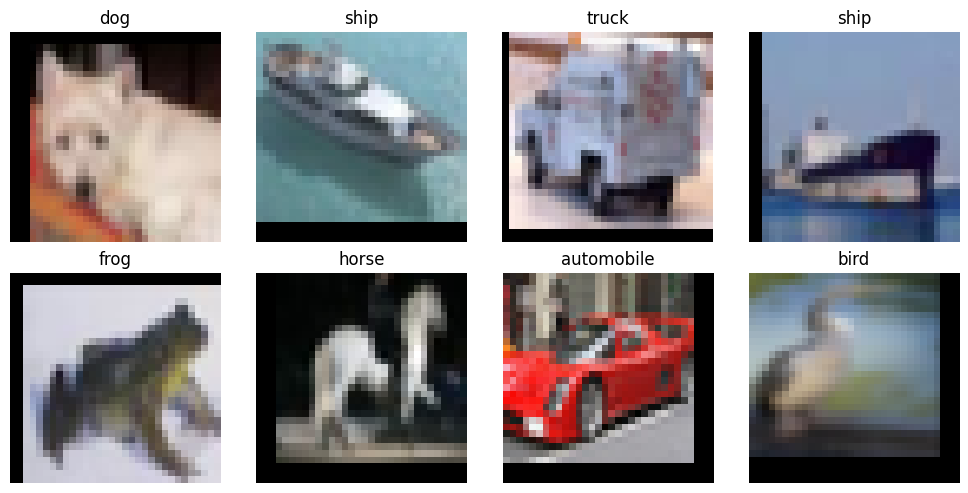

In [3]:
# Display a few training images (inverse-normalize only for visualization)
images, labels = next(iter(train_loader))
mean = torch.tensor(CIFAR10_MEAN).view(1, 3, 1, 1)
std = torch.tensor(CIFAR10_STD).view(1, 3, 1, 1)
images_for_plot = (images[:8] * std + mean).clamp(0, 1)

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    img = images_for_plot[i].permute(1, 2, 0).cpu().numpy()
    ax.imshow(img)
    ax.set_title(class_names[int(labels[i])])
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(
            in_channels, out_channels, kernel_size=3, stride=stride,
            padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(
            out_channels, out_channels, kernel_size=3, stride=1,
            padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        # Identity shortcut when shape is unchanged; otherwise project x to match F(x).
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        identity = self.shortcut(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + identity
        out = self.relu(out)
        return out


class ResNet18CIFAR10(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.in_channels = 64

        # CIFAR-specific stem: preserve 32 x 32 spatial resolution.
        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)

        self.layer1 = self._make_layer(64,  blocks=2, stride=1)  # 32 x 32
        self.layer2 = self._make_layer(128, blocks=2, stride=2)  # 16 x 16
        self.layer3 = self._make_layer(256, blocks=2, stride=2)  # 8 x 8
        self.layer4 = self._make_layer(512, blocks=2, stride=2)  # 4 x 4

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(512, num_classes)

        # Common initialization for residual CNNs.
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(module, nn.BatchNorm2d):
                nn.init.ones_(module.weight)
                nn.init.zeros_(module.bias)

    def _make_layer(self, out_channels, blocks, stride):
        layers = [BasicBlock(self.in_channels, out_channels, stride=stride)]
        self.in_channels = out_channels
        for _ in range(1, blocks):
            layers.append(BasicBlock(self.in_channels, out_channels, stride=1))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)  # raw logits; CrossEntropyLoss handles log-softmax internally


model = ResNet18CIFAR10(num_classes=10).to(device)
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"Trainable parameters: {num_params:,}")

# Shape sanity check: this should print torch.Size([2, 10]).
with torch.no_grad():
    dummy_logits = model(torch.zeros(2, 3, 32, 32, device=device))
print("Forward-pass output shape:", tuple(dummy_logits.shape))
assert dummy_logits.shape == (2, 10)

ResNet18CIFAR10(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (shortcut): Identity()
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), st

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(
    model.parameters(),
    lr=LEARNING_RATE,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY,
    nesterov=False,
)
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS, eta_min=LEARNING_RATE * 0.01
)

BEST_MODEL_PATH = OUTPUT_DIR / "resnet18_cifar10_best.pth"
LAST_CHECKPOINT_PATH = OUTPUT_DIR / "resnet18_cifar10_last_checkpoint.pth"
HISTORY_PATH = OUTPUT_DIR / "resnet18_cifar10_history.npz"

history = {
    "train_loss": [], "train_acc": [],
    "val_loss": [], "val_acc": [], "lr": [],
}
best_val_acc = -1.0
start_epoch = 0
print("Checkpoint output:", BEST_MODEL_PATH)

Checkpoint output: /kaggle/working/resnet18_cifar10_best.pth


In [6]:
def run_one_epoch(model, loader, criterion, optimizer=None, device=device):
    is_training = optimizer is not None
    model.train() if is_training else model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    context = torch.enable_grad() if is_training else torch.no_grad()
    with context:
        for inputs, targets in loader:
            inputs = inputs.to(device, non_blocking=(device.type == "cuda"))
            targets = targets.to(device, non_blocking=(device.type == "cuda"))

            if is_training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(inputs)
            loss = criterion(logits, targets)

            if is_training:
                loss.backward()
                optimizer.step()

            batch_size = targets.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (logits.argmax(dim=1) == targets).sum().item()
            total_examples += batch_size

    return total_loss / total_examples, total_correct / total_examples


for epoch in range(start_epoch, EPOCHS):
    epoch_start = time.time()
    current_lr = optimizer.param_groups[0]["lr"]

    train_loss, train_acc = run_one_epoch(model, train_loader, criterion, optimizer=optimizer)
    val_loss, val_acc = run_one_epoch(model, val_loader, criterion, optimizer=None)
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["lr"].append(current_lr)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "best_val_acc": best_val_acc,
            "class_names": class_names,
            "seed": SEED,
        }, BEST_MODEL_PATH)
        best_marker = "  * best checkpoint saved"
    else:
        best_marker = ""

    # Keep a last checkpoint too, useful if you later add resume logic.
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_val_acc": best_val_acc,
        "class_names": class_names,
        "seed": SEED,
    }, LAST_CHECKPOINT_PATH)
    np.savez(HISTORY_PATH, **{k: np.asarray(v) for k, v in history.items()})

    elapsed = time.time() - epoch_start
    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"lr={current_lr:.5f} | "
        f"train loss={train_loss:.4f}, acc={train_acc * 100:.2f}% | "
        f"val loss={val_loss:.4f}, acc={val_acc * 100:.2f}% | "
        f"{elapsed:.1f}s{best_marker}"
    )

print(f"\nBest validation accuracy: {best_val_acc * 100:.2f}%")
print("Best model saved to:", BEST_MODEL_PATH)
print("Last checkpoint saved to:", LAST_CHECKPOINT_PATH)

Epoch 01/20 | lr=0.10000 | train loss=2.0096, acc=27.15% | val loss=1.6038, acc=40.94% | 39.5s  * best checkpoint saved
Epoch 02/20 | lr=0.09939 | train loss=1.4932, acc=44.82% | val loss=1.3960, acc=47.92% | 40.3s  * best checkpoint saved
Epoch 03/20 | lr=0.09758 | train loss=1.2100, acc=56.08% | val loss=1.0390, acc=63.06% | 41.9s  * best checkpoint saved
Epoch 04/20 | lr=0.09460 | train loss=0.9441, acc=66.62% | val loss=0.8668, acc=68.72% | 41.4s  * best checkpoint saved
Epoch 05/20 | lr=0.09055 | train loss=0.7579, acc=73.58% | val loss=0.7211, acc=75.38% | 41.8s  * best checkpoint saved
Epoch 06/20 | lr=0.08550 | train loss=0.6461, acc=77.51% | val loss=0.9471, acc=67.84% | 41.5s
Epoch 07/20 | lr=0.07960 | train loss=0.5740, acc=80.19% | val loss=0.6172, acc=78.52% | 41.7s  * best checkpoint saved
Epoch 08/20 | lr=0.07297 | train loss=0.5288, acc=81.76% | val loss=0.5961, acc=79.48% | 41.7s  * best checkpoint saved
Epoch 09/20 | lr=0.06580 | train loss=0.4730, acc=83.76% | val lo

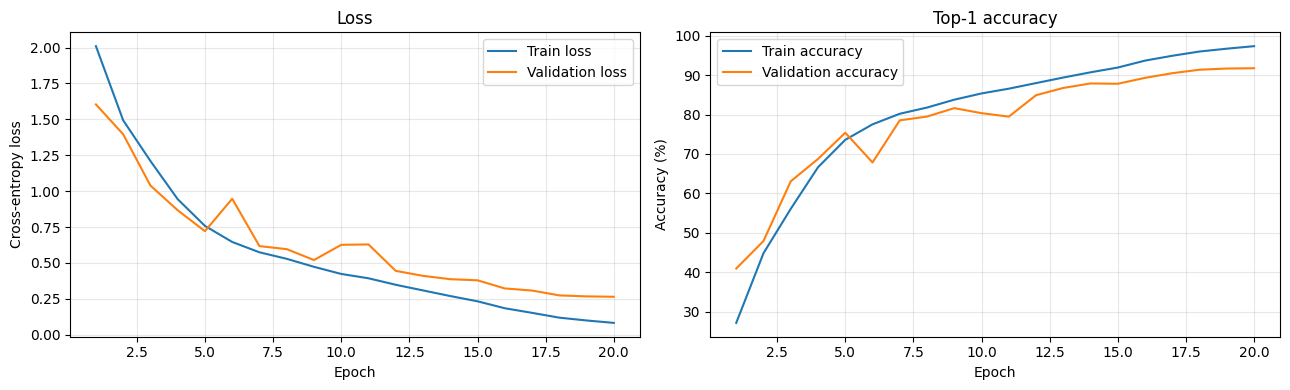

In [7]:
epochs_axis = np.arange(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epochs_axis, history["train_loss"], label="Train loss")
axes[0].plot(epochs_axis, history["val_loss"], label="Validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].set_title("Loss")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(epochs_axis, np.array(history["train_acc"]) * 100, label="Train accuracy")
axes[1].plot(epochs_axis, np.array(history["val_acc"]) * 100, label="Validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_title("Top-1 accuracy")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

In [8]:
checkpoint = torch.load(BEST_MODEL_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

test_loss, test_acc = run_one_epoch(model, test_loader, criterion, optimizer=None)
print(f"Best checkpoint epoch: {checkpoint['epoch']}")
print(f"Best validation accuracy: {checkpoint['best_val_acc'] * 100:.2f}%")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc * 100:.2f}%")

Best checkpoint epoch: 20
Best validation accuracy: 91.74%
Test loss: 0.2749
Test accuracy: 91.75%


In [9]:
# Per-class test accuracy
correct_by_class = torch.zeros(10, dtype=torch.long)
total_by_class = torch.zeros(10, dtype=torch.long)

model.eval()
with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device, non_blocking=(device.type == "cuda"))
        targets = targets.to(device, non_blocking=(device.type == "cuda"))
        predictions = model(inputs).argmax(dim=1)
        for class_id in range(10):
            mask = (targets == class_id)
            total_by_class[class_id] += mask.sum().cpu()
            correct_by_class[class_id] += ((predictions == targets) & mask).sum().cpu()

for class_id, name in enumerate(class_names):
    denom = int(total_by_class[class_id])
    class_acc = 100.0 * int(correct_by_class[class_id]) / max(denom, 1)
    print(f"{name:>10s}: {class_acc:6.2f}% ({int(correct_by_class[class_id])}/{denom})")

  airplane:  93.40% (934/1000)
automobile:  96.80% (968/1000)
      bird:  88.40% (884/1000)
       cat:  82.80% (828/1000)
      deer:  93.00% (930/1000)
       dog:  85.30% (853/1000)
      frog:  94.20% (942/1000)
     horse:  93.10% (931/1000)
      ship:  95.70% (957/1000)
     truck:  94.80% (948/1000)


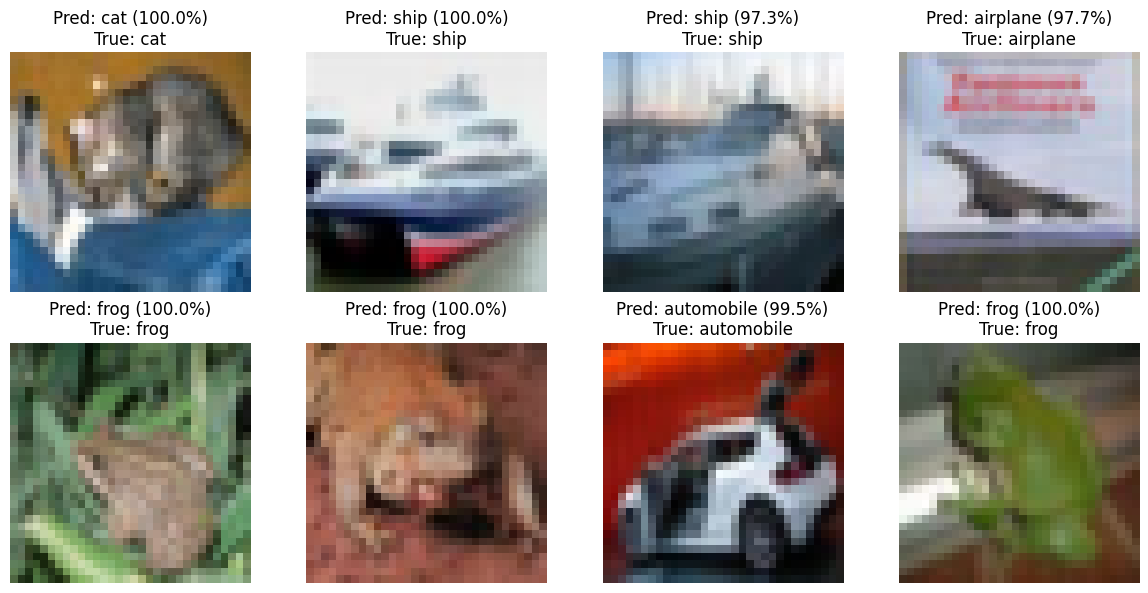

In [10]:
images, labels = next(iter(test_loader))
model.eval()
with torch.no_grad():
    logits = model(images.to(device))
    probabilities = torch.softmax(logits, dim=1).cpu()
    predictions = probabilities.argmax(dim=1)

images_for_plot = (images[:8] * std + mean).clamp(0, 1)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(images_for_plot[i].permute(1, 2, 0).numpy())
    true_name = class_names[int(labels[i])]
    pred_name = class_names[int(predictions[i])]
    confidence = float(probabilities[i, predictions[i]]) * 100
    ax.set_title(f"Pred: {pred_name} ({confidence:.1f}%)\nTrue: {true_name}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [11]:
WEIGHTS_PATH = OUTPUT_DIR / "resnet18_cifar10_weights.pth"
torch.save(model.state_dict(), WEIGHTS_PATH)
print("Weights saved to:", WEIGHTS_PATH)
print("Files:")
for path in [BEST_MODEL_PATH, LAST_CHECKPOINT_PATH, HISTORY_PATH, WEIGHTS_PATH]:
    if path.exists():
        print(f"  {path.name:42s} {path.stat().st_size / (1024 * 1024):.2f} MiB")

Weights saved to: /kaggle/working/resnet18_cifar10_weights.pth
Files:
  resnet18_cifar10_best.pth                  85.35 MiB
  resnet18_cifar10_last_checkpoint.pth       85.35 MiB
  resnet18_cifar10_history.npz               0.00 MiB
  resnet18_cifar10_weights.pth               42.70 MiB
